# Spleen segmentation in 3D CT with MONAI
Learn to predict a binary mask for every voxel using a 3D U-Net. Follow the notebook from top to bottom: libraries → dataset audit → visualization → patient splits → preprocessing → training → held-out testing.

**Dice** measures overlap: $2|P \cap G|/(|P|+|G|)$. A score of 1 means perfect overlap. Training uses Dice plus cross-entropy loss; evaluation reports foreground Dice per volume.

Based on the [official MONAI tutorial](https://github.com/Project-MONAI/tutorials/blob/main/3d_segmentation/spleen_segmentation_3d.ipynb) and [Medical Segmentation Decathlon](http://medicaldecathlon.com/). The supplied `Task09_Spleen.tar` is used locally. Official `imagesTs` have no public masks: quantitative testing therefore uses a held-out part of the labeled training set. Educational experiment; scores are produced only after actual execution.

## 1. Install and import libraries
Select a Python kernel supported by PyTorch and MONAI. Run the installation cell once and restart the kernel if packages were upgraded. A CUDA-enabled PyTorch installation and GPU are recommended for the full 100-epoch experiment. CPU execution is supported but much slower.

In [1]:
import importlib.metadata as package_metadata
for package in ['torch', 'monai', 'nibabel', 'matplotlib', 'pandas']:
    print(package, package_metadata.version(package))

torch 2.14.1
monai 1.6.1
nibabel 5.4.2
matplotlib 3.11.2
pandas 3.0.6


In [2]:
import json, random, tarfile, time
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import torch
import monai
from IPython.display import display
from monai.data import Dataset, PersistentDataset, DataLoader, list_data_collate
from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
    Spacingd, ScaleIntensityRanged, CropForegroundd, SpatialPadd,
    RandCropByPosNegLabeld, RandFlipd, RandRotate90d, EnsureTyped)
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.inferers import sliding_window_inference
from monai.utils import set_determinism
SEED = 42
set_determinism(seed=SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| MONAI:', monai.__version__, '| device:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu | MONAI: 1.6.1 | device: cpu


## 2. Configuration and safe local extraction
The default trains on all training cases. CPU mode uses a compact network, 48-voxel training patches and 30 epochs; GPU mode uses larger patches and 100 epochs. Set `SMOKE_TEST=True` only for a quick pipeline check. CPU results are a practical baseline, with lower spatial resolution than the GPU configuration.

In [3]:
ROOT = Path.cwd()
ARCHIVE = ROOT / 'Task09_Spleen.tar'
DATA = ROOT / 'Task09_Spleen'
SMOKE_TEST = False
CPU_MODE = device.type == 'cpu'
MAX_EPOCHS = 1 if SMOKE_TEST else (30 if CPU_MODE else 100)
ROI = (32, 32, 32) if SMOKE_TEST else ((48, 48, 48) if CPU_MODE else (96, 96, 96))
INFER_ROI = (96, 96, 96)
SPACING = (3.0, 3.0, 3.0) if SMOKE_TEST or CPU_MODE else (1.5, 1.5, 2.0)
CHANNELS = (4, 8, 16, 32, 64) if SMOKE_TEST else ((8, 16, 32, 64, 128) if CPU_MODE else (16, 32, 64, 128, 256))
PATCHES = 1 if SMOKE_TEST else 2
VAL_INTERVAL = 1 if SMOKE_TEST else 5
LEARNING_RATE = 1e-3 if CPU_MODE else 1e-4
RUN = ROOT / 'artifacts' / ('smoke' if SMOKE_TEST else ('cpu_baseline' if CPU_MODE else 'full'))
RUN.mkdir(parents=True, exist_ok=True)
with open(RUN / 'run_config.json', 'w') as f:
    json.dump({'seed': SEED, 'device': str(device), 'epochs': MAX_EPOCHS,
        'training_roi': ROI, 'inference_roi': INFER_ROI, 'spacing': SPACING,
        'channels': CHANNELS, 'patches_per_case': PATCHES, 'learning_rate': LEARNING_RATE,
        'smoke_test': SMOKE_TEST, 'torch': torch.__version__, 'monai': monai.__version__}, f, indent=2)
if not DATA.exists():
    if not ARCHIVE.exists() and (ROOT / 'dataset_parts' / 'manifest.json').exists():
        from restore_dataset import restore_archive
        restore_archive(ROOT)
    if not ARCHIVE.exists():
        raise FileNotFoundError(f'Place Task09_Spleen.tar in {ROOT}')
    with tarfile.open(ARCHIVE) as archive:
        # Python's data filter rejects traversal, unsafe links and device files.
        archive.extractall(ROOT, filter='data')
print('Dataset:', DATA, '| Output:', RUN)

Dataset: .\Task09_Spleen | Output: .\artifacts\cpu_baseline


## 3. Check every label before training
Match scans and masks by filename, not directory order. Audit missing/orphan labels, unreadable files, 3D shapes, spatial alignment, finite values, binary label values, and empty spleen masks. Invalid cases stop execution rather than being silently discarded. Empty background slices within a valid mask are normal.

In [4]:
def nifti_files(folder):
    return {p.name: p for p in folder.glob('*.nii*') if not p.name.startswith('._')}
images = nifti_files(DATA / 'imagesTr')
labels = nifti_files(DATA / 'labelsTr')
missing = sorted(images.keys() - labels.keys())
orphan = sorted(labels.keys() - images.keys())
print('Training scans:', len(images), '| Masks:', len(labels))
print('Missing masks:', missing, '| Orphan masks:', orphan)
issues, rows, files = [], [], []
if not images:
    issues.append('No labeled training scans found.')
if missing or orphan:
    issues.append(f'Missing masks: {missing}; orphan masks: {orphan}')
for name in sorted(images.keys() & labels.keys()):
    try:
        image, label = nib.load(images[name]), nib.load(labels[name])
        x, y = image.get_fdata(dtype=np.float32), label.get_fdata(dtype=np.float32)
        errors = []
        if x.ndim != 3 or x.shape != y.shape: errors.append('shape mismatch / not 3D')
        if not np.allclose(image.affine, label.affine, atol=1e-4): errors.append('affine mismatch')
        if not np.isfinite(x).all() or not np.isfinite(y).all(): errors.append('nonfinite voxels')
        if not np.isin(y, [0, 1]).all(): errors.append('mask values outside {0,1}')
        if not (y == 1).any(): errors.append('empty spleen mask')
        if errors: issues.append(f'{name}: {errors}')
        rows.append({'case': name, 'shape': str(x.shape), 'spacing_mm': str(image.header.get_zooms()[:3]),
            'spleen_voxels': int((y == 1).sum()),
            'spleen_ml': float((y == 1).sum() * abs(np.linalg.det(image.affine[:3, :3])) / 1000),
            'status': '; '.join(errors) or 'OK'})
        files.append({'image': images[name].relative_to(ROOT).as_posix(),
            'label': labels[name].relative_to(ROOT).as_posix(), 'case': name})
    except Exception as exc:
        issues.append(f'{name}: {exc}')
audit = pd.DataFrame(rows)
audit.to_csv(RUN / 'label_audit.csv', index=False)
display(audit)
if issues:
    raise ValueError('Fix dataset problems before training:\n' + '\n'.join(issues))
with open(DATA / 'dataset.json') as f:
    metadata = json.load(f)
if len(files) != metadata['numTraining']:
    raise ValueError('Training case count differs from dataset.json')
print('All labels passed. Unlabeled official test scans:', len(nifti_files(DATA / 'imagesTs')))

Training scans: 41 | Masks: 41
Missing masks: [] | Orphan masks: []


,case,shape,spacing_mm,spleen_voxels,spleen_ml,status
0,spleen_10.nii.gz,"(512, 512, 55)","(np.float32(0.976562), np.float32(0.976562), n...",53071,253.062001,OK
1,spleen_12.nii.gz,"(512, 512, 168)","(np.float32(0.753906), np.float32(0.753906), n...",537685,458.409483,OK
2,spleen_13.nii.gz,"(512, 512, 77)","(np.float32(0.742188), np.float32(0.742188), n...",203903,280.796347,OK
3,spleen_14.nii.gz,"(512, 512, 54)","(np.float32(0.851562), np.float32(0.851562), n...",124163,450.188889,OK
4,spleen_16.nii.gz,"(512, 512, 61)","(np.float32(0.792969), np.float32(0.792969), n...",40044,201.437279,OK
5,spleen_17.nii.gz,"(512, 512, 95)","(np.float32(0.613281), np.float32(0.613281), n...",96414,90.656541,OK
6,spleen_18.nii.gz,"(512, 512, 164)","(np.float32(0.966797), np.float32(0.966797), n...",157714,221.122069,OK
7,spleen_19.nii.gz,"(512, 512, 51)","(np.float32(0.796875), np.float32(0.796875), n...",96852,307.509829,OK
8,spleen_2.nii.gz,"(512, 512, 90)","(np.float32(0.794922), np.float32(0.794922), n...",96672,305.435656,OK
9,spleen_20.nii.gz,"(512, 512, 168)","(np.float32(0.933594), np.float32(0.933594), n...",221465,289.542589,OK


All labels passed. Unlabeled official test scans: 20


## 4. Visualize CT scans and ground-truth masks
Use an abdominal intensity window and slices passing through the spleen. Display three planes and the distribution of organ volumes.

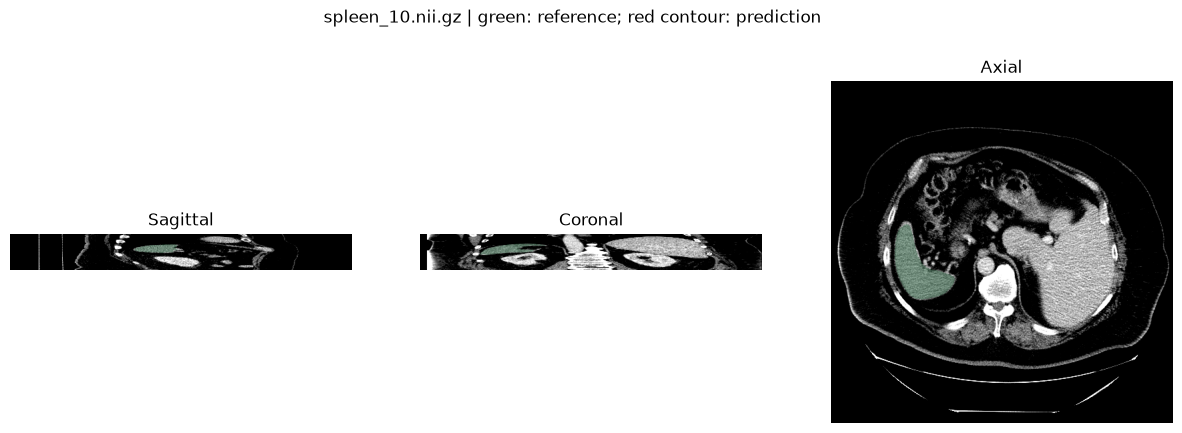

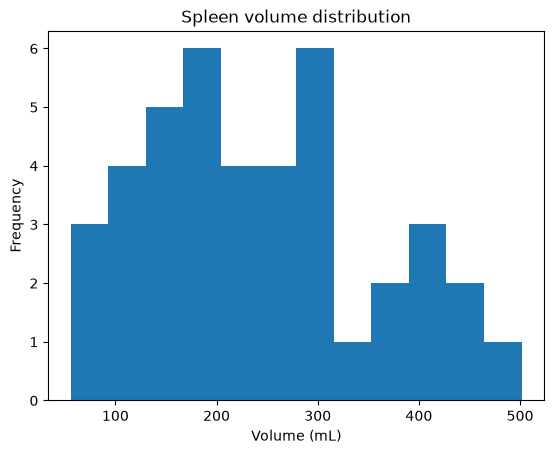

In [5]:
def show_planes(image, mask, prediction=None, title=''):
    center = np.round(np.argwhere(mask > 0).mean(axis=0)).astype(int)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for axis, (ax, plane) in enumerate(zip(axes, ['Sagittal', 'Coronal', 'Axial'])):
        scan = np.take(image, center[axis], axis=axis).T
        truth = np.take(mask, center[axis], axis=axis).T
        ax.imshow(scan, cmap='gray', origin='lower')
        ax.imshow(np.ma.masked_where(truth == 0, truth), cmap='Greens', alpha=.4, origin='lower', vmin=0, vmax=1)
        if prediction is not None:
            pred = np.take(prediction, center[axis], axis=axis).T
            if pred.any() and not pred.all(): ax.contour(pred, levels=[.5], colors='red', linewidths=1)
        ax.set_title(plane); ax.axis('off')
    fig.suptitle(title + ' | green: reference; red contour: prediction')
    fig.savefig(RUN / (title.replace('.nii.gz', '') + '_planes.png'), dpi=120, bbox_inches='tight')
    plt.show()
example = files[0]
raw_x = nib.load(example['image']).get_fdata(dtype=np.float32)
raw_y = nib.load(example['label']).get_fdata(dtype=np.float32)
show_planes(np.clip((raw_x + 57) / 221, 0, 1), raw_y, title=example['case'])
audit['spleen_ml'].plot.hist(bins=12, title='Spleen volume distribution')
plt.xlabel('Volume (mL)'); plt.savefig(RUN / 'organ_volume_distribution.png', dpi=120); plt.show()
del raw_x, raw_y, x, y, image, label

## 5. Split by patient volume
Reserve approximately 20% for testing and 20% for validation. No patches from a test or validation volume enter training. Save the seeded split. Smoke mode uses subsets of these already disjoint partitions.

In [6]:
order = np.random.default_rng(SEED).permutation(len(files))
n_test = max(1, round(len(files) * .2))
n_val = max(1, round(len(files) * .2))
test_files = [files[i] for i in order[:n_test]]
val_files = [files[i] for i in order[n_test:n_test+n_val]]
train_files = [files[i] for i in order[n_test+n_val:]]
assert train_files and val_files and test_files
if SMOKE_TEST:
    train_files, val_files, test_files = train_files[:2], val_files[:1], test_files[:1]
splits = {'train': train_files, 'validation': val_files, 'test': test_files}
with open(RUN / 'splits.json', 'w') as f: json.dump(splits, f, indent=2)
print({k: len(v) for k, v in splits.items()})

{'train': 25, 'validation': 8, 'test': 8}


## 6. Preprocess and visualize training patches
Orient to RAS, resample to common voxel spacing, scale CT intensities, and crop the foreground using **only the image**. Use nearest-neighbor interpolation for masks so labels stay binary. Random balanced spleen/background crops and augmentation apply only to training. Validation and testing use whole preprocessed volumes and sliding-window inference.

.\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Patch shape: (2, 1, 48, 48, 48) | Labels: metatensor([0., 1.])


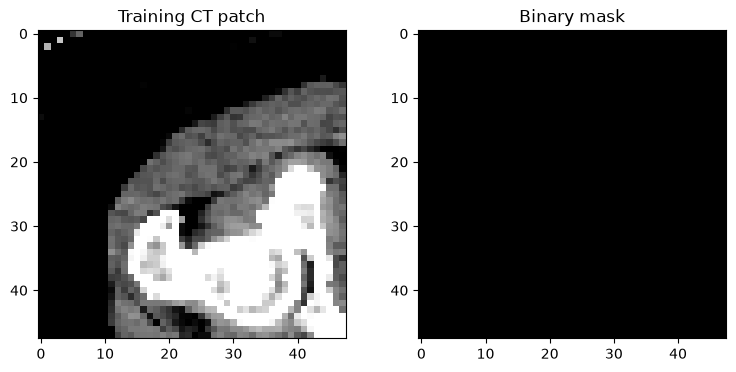

In [7]:
base = [LoadImaged(keys=['image', 'label']), EnsureChannelFirstd(keys=['image', 'label']),
    Orientationd(keys=['image', 'label'], axcodes='RAS'),
    Spacingd(keys=['image', 'label'], pixdim=SPACING, mode=('bilinear', 'nearest')),
    ScaleIntensityRanged(keys='image', a_min=-57, a_max=164, b_min=0, b_max=1, clip=True),
    CropForegroundd(keys=['image', 'label'], source_key='image', allow_smaller=True)]
train_transform = Compose(base + [SpatialPadd(keys=['image', 'label'], spatial_size=ROI),
    RandCropByPosNegLabeld(keys=['image', 'label'], label_key='label', spatial_size=ROI,
        pos=1, neg=1, num_samples=PATCHES, image_key='image', image_threshold=0),
    RandFlipd(keys=['image', 'label'], prob=.5, spatial_axis=0),
    RandRotate90d(keys=['image', 'label'], prob=.2, max_k=3),
    EnsureTyped(keys=['image', 'label'])])
eval_transform = Compose(base + [EnsureTyped(keys=['image', 'label'])])
train_ds = Dataset(train_files, train_transform)
val_ds = Dataset(val_files, eval_transform)
test_ds = Dataset(test_files, eval_transform)
# Cache deterministic preprocessing on disk rather than filling RAM.
train_ds = PersistentDataset(train_files, train_transform, cache_dir=RUN / 'cache_train')
val_ds = PersistentDataset(val_files, eval_transform, cache_dir=RUN / 'cache_val')
test_ds = PersistentDataset(test_files, eval_transform, cache_dir=RUN / 'cache_test')
# Zero workers is reliable in Windows notebooks.
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0,
    collate_fn=list_data_collate, pin_memory=device.type == 'cuda')
val_loader = DataLoader(val_ds, batch_size=1, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=1, num_workers=0)
patch = next(iter(train_loader))
print('Patch shape:', tuple(patch['image'].shape), '| Labels:', torch.unique(patch['label']))
z = int(patch['label'][0, 0].sum(dim=(0, 1)).argmax())
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(patch['image'][0, 0, :, :, z].T, cmap='gray'); ax[0].set_title('Training CT patch')
ax[1].imshow(patch['label'][0, 0, :, :, z].T, cmap='gray'); ax[1].set_title('Binary mask')
plt.savefig(RUN / 'training_patch.png', dpi=120)
plt.show()

## 7. Build the 3D U-Net
One CT input channel; two output logits for background and spleen. Adam minimizes Dice plus cross-entropy. Foreground Dice is calculated per complete volume, excluding background.

In [8]:
model = UNet(spatial_dims=3, in_channels=1, out_channels=2,
    channels=CHANNELS, strides=(2, 2, 2, 2), num_res_units=2, norm='INSTANCE').to(device)
loss_fn = DiceCELoss(to_onehot_y=True, softmax=True, include_background=False)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
def foreground_dice(pred, truth):
    p, g = pred.bool(), truth.bool()
    denominator = p.sum().item() + g.sum().item()
    return 1.0 if denominator == 0 else 2.0 * (p & g).sum().item() / denominator
@torch.inference_mode()
def evaluate(loader):
    model.eval()
    results = []
    for batch in loader:
        # Keep full volumes on CPU; only sliding patches and model use GPU memory.
        logits = sliding_window_inference(batch['image'], INFER_ROI, 1, model,
            overlap=.25, sw_device=device, device=torch.device('cpu'))
        pred = logits.argmax(dim=1)[0]
        results.append({'case': batch['case'][0], 'dice': foreground_dice(pred, batch['label'][0, 0])})
    return pd.DataFrame(results)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

Trainable parameters: 1202793


## 8. Train and validate
Select the checkpoint using validation Dice only. Save loss, validation curves, configuration and weights. The test split stays untouched until the next section.

Epoch 1/30 | loss 1.3546 | val Dice nan


Epoch 2/30 | loss 1.1123 | val Dice nan


Epoch 3/30 | loss 1.0080 | val Dice nan


Epoch 4/30 | loss 0.9374 | val Dice nan


Epoch 5/30 | loss 0.8930 | val Dice 0.0873


...

Epoch 27/30 | loss 0.6067 | val Dice nan


Epoch 28/30 | loss 0.6832 | val Dice nan


Epoch 29/30 | loss 0.5825 | val Dice nan


Epoch 30/30 | loss 0.5593 | val Dice 0.1561


Elapsed 9.8 min; best validation Dice 0.2309, epoch 20


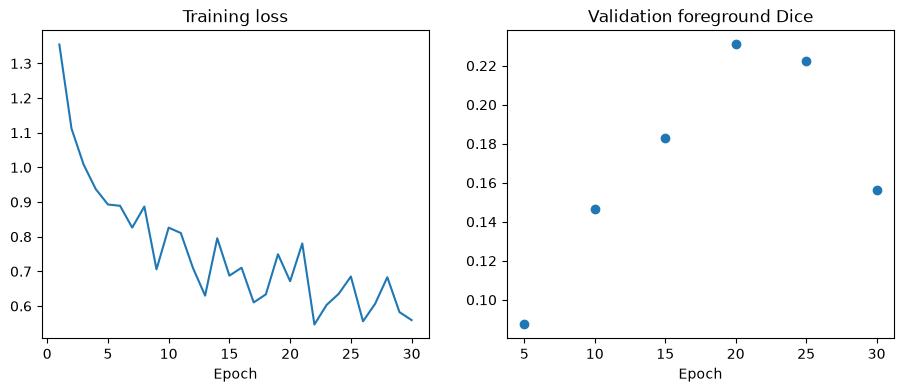

In [9]:
history, best_dice, best_epoch = [], -1.0, 0
start = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    losses = []
    for batch in train_loader:
        x, y = batch['image'].to(device), batch['label'].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(x), y)
        if not torch.isfinite(loss): raise RuntimeError('Nonfinite training loss')
        loss.backward(); optimizer.step()
        losses.append(loss.item())
    val_dice = np.nan
    if epoch % VAL_INTERVAL == 0 or epoch == MAX_EPOCHS:
        val_dice = float(evaluate(val_loader)['dice'].mean())
        if val_dice > best_dice:
            best_dice, best_epoch = val_dice, epoch
            torch.save({'model': model.state_dict(), 'epoch': epoch, 'validation_dice': best_dice,
                'channels': CHANNELS, 'roi': ROI, 'infer_roi': INFER_ROI,
                'spacing': SPACING, 'seed': SEED, 'learning_rate': LEARNING_RATE,
                'smoke_test': SMOKE_TEST}, RUN / 'best_model.pt')
    history.append({'epoch': epoch, 'loss': float(np.mean(losses)), 'validation_dice': val_dice})
    pd.DataFrame(history).to_csv(RUN / 'training_history.csv', index=False)
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
        'epoch': epoch, 'history': history}, RUN / 'last_model.pt')
    print(f'Epoch {epoch}/{MAX_EPOCHS} | loss {history[-1]["loss"]:.4f} | val Dice {val_dice:.4f}', flush=True)
print(f'Elapsed {(time.perf_counter()-start)/60:.1f} min; best validation Dice {best_dice:.4f}, epoch {best_epoch}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
hist = pd.DataFrame(history)
axes[0].plot(hist.epoch, hist.loss); axes[0].set_title('Training loss')
axes[1].plot(hist.epoch, hist.validation_dice, 'o-'); axes[1].set_title('Validation foreground Dice')
for ax in axes: ax.set_xlabel('Epoch')
plt.savefig(RUN / 'learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Test the trained checkpoint
Load the best validation checkpoint and report per-case test Dice, mean and standard deviation. These scores are measured on the resampled, cropped evaluation grid. Smoke mode checks execution only. Do not tune the model using these test results.

In [10]:
checkpoint = torch.load(RUN / 'best_model.pt', map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model'])
test_results = evaluate(test_loader)
test_results.to_csv(RUN / 'test_metrics.csv', index=False)
display(test_results)
summary = {'mean_dice': float(test_results.dice.mean()),
    'std_dice': float(test_results.dice.std(ddof=0)), 'n_test': len(test_results),
    'best_epoch': checkpoint['epoch'], 'smoke_test': SMOKE_TEST}
with open(RUN / 'test_summary.json', 'w') as f: json.dump(summary, f, indent=2)
print(summary)
if SMOKE_TEST: print('Smoke run only. Switch SMOKE_TEST=False and run all cells for the full experiment.')

,case,dice
0,spleen_56.nii.gz,0.090171
1,spleen_19.nii.gz,0.272234
2,spleen_9.nii.gz,0.201166
3,spleen_3.nii.gz,0.196320
4,spleen_16.nii.gz,0.156472
5,spleen_63.nii.gz,0.310736
6,spleen_28.nii.gz,0.204954
7,spleen_17.nii.gz,0.105736


{'mean_dice': 0.19222356583639583, 'std_dice': 0.07060326019335084, 'n_test': 8, 'best_epoch': 20, 'smoke_test': False}


## 10. Visualize held-out predictions and save a mask
Show the lowest-Dice test case to make errors visible. The saved NIfTI uses the preprocessed image affine; it is on the resampled grid, not the original scanner grid.

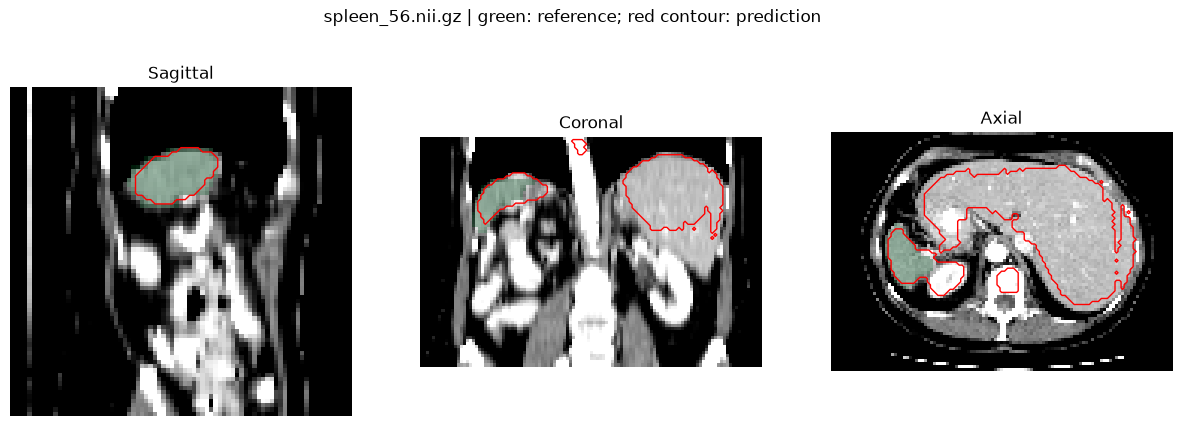

Saved checkpoint, audit, splits, training curves, test scores and prediction in .\artifacts\cpu_baseline


In [11]:
worst = test_results.sort_values('dice').iloc[0]['case']
# Reload transforms directly: cached tensors may omit affine metadata.
sample = eval_transform(test_files[next(i for i, f in enumerate(test_files) if f['case'] == worst)])
model.eval()
with torch.inference_mode():
    output = sliding_window_inference(sample['image'].unsqueeze(0), INFER_ROI, 1, model,
        overlap=.25, sw_device=device, device=torch.device('cpu'))
prediction = output.argmax(dim=1)[0].numpy().astype(np.uint8)
show_planes(sample['image'][0].numpy(), sample['label'][0].numpy(), prediction, title=worst)
affine = sample['image'].affine.cpu().numpy()
nib.save(nib.Nifti1Image(prediction, affine), RUN / 'held_out_prediction_resampled.nii.gz')
print('Saved checkpoint, audit, splits, training curves, test scores and prediction in', RUN)

## 11. Interpret your results
- Compare CT, reference masks, and predictions across slices. Dice alone can hide boundary errors.
- Full training uses all labeled cases in the training partition; validation chooses the epoch and testing measures generalization.
- The official unlabeled test scans can be segmented after training, but cannot provide Dice without reference masks.
- For further experiments, change learning rate or augmentation using validation data. Keep the held-out test split fixed.
- For original-space exports, invert preprocessing with MONAI `Invertd` before saving. The export above explicitly stays in the evaluation grid.

## Measured results from this run

The notebook was executed with the project `.venv`: **30 CPU epochs**, 25 training volumes, 8 validation volumes and 8 held-out test volumes. All 41 labeled scans passed the scan/mask audit.

The best checkpoint was epoch **20**, chosen using validation Dice **0.231**. Held-out mean Dice was **0.192**, with standard deviation **0.071** across **8** cases. This is a trained baseline with poor segmentation overlap. The displayed worst-case prediction includes substantial false-positive regions outside the spleen; successful training does not imply accurate organ outlining.

Weights, patient splits, configuration, audit, curves, per-case scores and a resampled prediction mask are saved in `artifacts/cpu_baseline`. To improve this baseline, investigate larger training context, finer voxel spacing and longer training using validation data; keep test cases separate.
